# NLP Assignment-2 (Set-8): BERT Variant Comparison
**Group 77**

**Task:** Compare a *general-domain* BERT with a *domain-specific* (biomedical) BERT on biomedical text classification.

| Item | Choice |
|---|---|
| Dataset | PubMedQA, `pqa_labeled` configuration (Hugging Face `datasets`) |
| Task framing | 3-class classification: given a question and its abstract context, predict **yes / no / maybe** |
| Model A (general) | `bert-base-uncased` |
| Model B (domain-specific) | `microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract` |
| Metrics | Accuracy, Precision, Recall, F1 (macro and weighted) |

**Pipeline (matches the 7 implementation requirements):**
1. Dataset loading using `datasets`
2. Data preprocessing and tokenization
3. Model loading using `transformers`
4. Fine-tuning
5. Evaluation (Accuracy / Precision / Recall / F1)
6. Prediction on at least 5 custom examples
7. Error analysis

> **How to run:** works on Google Colab (set the runtime to GPU; a T4 is enough), on an Apple-silicon Mac (the MPS GPU is used automatically) and on CPU (slow). Choose *Run all*. The device is detected automatically; fp16 is used only on CUDA. To get mean ± std over several seeds, change `SEEDS` in the configuration cell.

## 0. Setup

In [1]:
# Colab / fresh environments: install anything that is missing (no-op on a machine that already has them)
import importlib.util, subprocess, sys
_need = {"transformers": "transformers", "datasets": "datasets", "accelerate": "accelerate",
         "sklearn": "scikit-learn", "matplotlib": "matplotlib", "pandas": "pandas", "scipy": "scipy"}
_missing = [pip for mod, pip in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *_missing])
    print("Installed:", _missing)
else:
    print("All required packages already installed.")

All required packages already installed.


In [2]:
import os, re, time, gc, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from scipy.stats import binomtest

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

if torch.cuda.is_available():
    DEVICE = "cuda"          # Colab / NVIDIA GPU
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"           # Apple-silicon Mac
else:
    DEVICE = "cpu"
DEVICE_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else {"mps": "Apple GPU (MPS)", "cpu": "no GPU found (training will be slow)"}[DEVICE]
print("Device:", DEVICE, "|", DEVICE_NAME)


def free_memory():
    # Release cached accelerator memory (works on CUDA, MPS and CPU)
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1112 14:17:05.829000 98362 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps | Apple GPU (MPS)


### Configuration

In [3]:
# ----- Models to compare -----
MODELS = {
    "BERT (general)":        "bert-base-uncased",
    "PubMedBERT (biomed)":   "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract",
}

# ----- Data -----
TEST_SIZE = 200        # held-out test examples (stratified)
VAL_SIZE  = 100        # validation examples used for model selection (stratified)
MAX_LEN   = 512        # BERT maximum sequence length

# ----- Training -----
SEEDS      = [42]      # use e.g. [42, 43, 44] for mean +/- std (3x the runtime)
EPOCHS     = 5
LR         = 3e-5
# Effective batch size is always 16. On CUDA (Colab T4, fp16) we can fit 8 x 512 tokens per step;
# on Mac (MPS) / CPU we use smaller micro-batches to keep memory low (same optimisation, just slower per step).
if DEVICE == "cuda":
    TRAIN_BS, GRAD_ACCUM, EVAL_BS = 8, 2, 32
else:
    TRAIN_BS, GRAD_ACCUM, EVAL_BS = 2, 8, 8
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.1

SPLIT_SEED = 42        # the data split is fixed across models and seeds
LABELS   = ["yes", "no", "maybe"]
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

## 1. Dataset loading (Hugging Face `datasets`)

PubMedQA contains biomedical research questions paired with PubMed abstracts. The expert-labelled subset (`pqa_labeled`, 1,000 examples) has a `final_decision` of *yes*, *no* or *maybe*.

The dataset was originally published as `pubmed_qa`; on the Hub it now lives at `qiaojin/PubMedQA`. The cell below tries both names.

In [4]:
ds = None
for name in ["qiaojin/PubMedQA", "pubmed_qa"]:
    try:
        ds = load_dataset(name, "pqa_labeled")
        print(f"Loaded dataset: {name}")
        break
    except Exception as e:
        print(f"Could not load '{name}': {type(e).__name__}: {str(e)[:150]}")

if ds is None:
    raise RuntimeError("PubMedQA could not be loaded. Check your internet connection / Hugging Face access.")

print(ds)
raw = ds["train"]
print("\nColumns:", raw.column_names)
print("\nExample record:")
ex = raw[0]
print("Question      :", ex["question"])
print("Context (1st) :", ex["context"]["contexts"][0][:250], "...")
print("Final decision:", ex["final_decision"])

Loaded dataset: qiaojin/PubMedQA
DatasetDict({
    train: Dataset({
        features: ['pubid', 'question', 'context', 'long_answer', 'final_decision'],
        num_rows: 1000
    })
})

Columns: ['pubid', 'question', 'context', 'long_answer', 'final_decision']

Example record:
Question      : Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?
Context (1st) : Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transve ...
Final decision: yes


## 2. Data preprocessing and tokenization

**Input construction.** Each example is encoded as a BERT sentence pair: `[CLS] question [SEP] abstract context [SEP]`. The abstract context is the concatenation of the abstract paragraphs **without** the conclusion. We deliberately do **not** use the `long_answer` field, because it is the abstract's conclusion and largely gives away the label.

**Splits.** The 1,000 labelled examples are split into train / validation / test using a stratified split with a fixed seed, so both models see exactly the same data.

In [5]:
records = []
for i, ex in enumerate(raw):
    records.append({
        "uid": i,
        "question": ex["question"].strip(),
        "context": " ".join(c.strip() for c in ex["context"]["contexts"]),
        "label": label2id[ex["final_decision"]],
        "label_name": ex["final_decision"],
    })
df = pd.DataFrame(records)

print("Total labelled examples:", len(df))
print("\nClass distribution:")
print(df["label_name"].value_counts().to_string())
print("\nContext length (words):")
print(df["context"].str.split().str.len().describe().round(1).to_string())

Total labelled examples: 1000

Class distribution:
label_name
yes      552
no       338
maybe    110

Context length (words):
count    1000.0
mean      200.2
std        51.8
min        49.0
25%       166.8
50%       200.5
75%       228.0
max       398.0


In [6]:
trainval_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["label"], random_state=SPLIT_SEED
)
train_df, val_df = train_test_split(
    trainval_df, test_size=VAL_SIZE, stratify=trainval_df["label"], random_state=SPLIT_SEED
)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

split_summary = pd.DataFrame({
    name: d["label_name"].value_counts().reindex(LABELS)
    for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]
})
split_summary.loc["total"] = split_summary.sum()
print(split_summary.to_string())

            train  validation  test
label_name                         
yes           387          55   110
no            236          34    68
maybe          77          11    22
total         700         100   200


In [7]:
def tokenize_split(tokenizer, split_df):
    '''Tokenize (question, context) pairs and return a HF Dataset with `labels`.'''
    d = Dataset.from_pandas(split_df[["question", "context", "label"]].reset_index(drop=True))

    def _tok(batch):
        return tokenizer(
            batch["question"],
            batch["context"],
            truncation="only_second",   # truncate the abstract, never the question
            max_length=MAX_LEN,
        )

    d = d.map(_tok, batched=True, remove_columns=["question", "context"])
    return d.rename_column("label", "labels")

### 2.1 How well does each tokenizer handle biomedical vocabulary?

A key difference between the two models is the vocabulary: `bert-base-uncased` has a general-English WordPiece vocabulary, while PubMedBERT's vocabulary was built from PubMed text. A tokenizer that fragments medical terms into many small pieces gives the model a harder job. Below we measure the average number of sub-word tokens per word on our test contexts.

In [8]:
tok_cache = {name: AutoTokenizer.from_pretrained(path) for name, path in MODELS.items()}

sample_words = ["hyperlipidemia", "adenocarcinoma", "cyclooxygenase", "meniscectomy", "thrombocytopenia", "metformin"]
for name, tk in tok_cache.items():
    print(f"\n{name}")
    for w in sample_words:
        print(f"  {w:<18} -> {tk.tokenize(w)}")

def fragmentation_stats(tk, texts, n=200):
    words = [w for t in texts[:n] for w in re.findall(r"[A-Za-z]+", t)]
    pieces = [len(tk.tokenize(w)) for w in words]
    return {
        "avg_tokens_per_word": np.mean(pieces),
        "pct_words_split_into_3+": 100 * np.mean(np.array(pieces) >= 3),
    }

frag = pd.DataFrame({name: fragmentation_stats(tk, test_df["context"].tolist())
                     for name, tk in tok_cache.items()}).T.round(3)
print("\nTokenizer fragmentation on test contexts:")
print(frag.to_string())


BERT (general)
  hyperlipidemia     -> ['hyper', '##lip', '##ide', '##mia']
  adenocarcinoma     -> ['aden', '##oca', '##rc', '##ino', '##ma']
  cyclooxygenase     -> ['cy', '##cl', '##oo', '##xy', '##genase']
  meniscectomy       -> ['men', '##is', '##ce', '##ct', '##omy']
  thrombocytopenia   -> ['th', '##rom', '##bo', '##cy', '##top', '##enia']
  metformin          -> ['met', '##form', '##in']

PubMedBERT (biomed)
  hyperlipidemia     -> ['hyperlipidemia']
  adenocarcinoma     -> ['adenocarcinoma']
  cyclooxygenase     -> ['cyclooxygenase']
  meniscectomy       -> ['menisc', '##ectomy']
  thrombocytopenia   -> ['thrombocytopenia']
  metformin          -> ['metformin']



Tokenizer fragmentation on test contexts:
                     avg_tokens_per_word  pct_words_split_into_3+
BERT (general)                     1.213                    6.098
PubMedBERT (biomed)                1.055                    1.085


## 3. Model loading, 4. Fine-tuning, 5. Evaluation

For each model we:
1. load the tokenizer and `AutoModelForSequenceClassification` (3 labels) from the Hub,
2. fine-tune with the Hugging Face `Trainer` (AdamW, linear warm-up and decay, fp16 on GPU),
3. select the best epoch by **validation macro-F1**,
4. evaluate once on the held-out **test** set.

Both models use identical hyper-parameters, data splits and seeds, so differences come from the pre-training (general vs biomedical), not from the training setup.

In [9]:
# Compatibility helpers: argument names changed across `transformers` versions
_ta_params = inspect.signature(TrainingArguments.__init__).parameters
_tr_params = inspect.signature(Trainer.__init__).parameters
EVAL_KEY = "eval_strategy" if "eval_strategy" in _ta_params else "evaluation_strategy"
TOK_KEY  = "processing_class" if "processing_class" in _tr_params else "tokenizer"


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision_macro": p, "recall_macro": r, "f1_macro": f}


def softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def full_test_metrics(y_true, y_pred):
    out = {"accuracy": accuracy_score(y_true, y_pred)}
    for avg in ["macro", "weighted"]:
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        out.update({f"precision_{avg}": p, f"recall_{avg}": r, f"f1_{avg}": f})
    return out

In [10]:
def run_experiment(display_name, model_path, seed):
    set_seed(seed)
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_path, num_labels=len(LABELS), id2label=id2label, label2id=label2id
    )

    train_ds = tokenize_split(tokenizer, train_df)
    val_ds   = tokenize_split(tokenizer, val_df)
    test_ds  = tokenize_split(tokenizer, test_df)

    steps_per_epoch = int(np.ceil(len(train_ds) / (TRAIN_BS * GRAD_ACCUM)))
    total_steps = steps_per_epoch * EPOCHS

    tag = re.sub(r"[^A-Za-z0-9]+", "_", display_name).strip("_")
    args = TrainingArguments(
        output_dir=f"./runs/{tag}_seed{seed}",
        **{EVAL_KEY: "epoch"},
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        learning_rate=LR,
        per_device_train_batch_size=TRAIN_BS,
        per_device_eval_batch_size=EVAL_BS,
        gradient_accumulation_steps=GRAD_ACCUM,
        num_train_epochs=EPOCHS,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=int(WARMUP_FRAC * total_steps),
        fp16=(DEVICE == "cuda"),   # mixed precision only on NVIDIA GPUs; MPS/CPU use fp32
        logging_steps=10,
        report_to="none",
        seed=seed,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
        **{TOK_KEY: tokenizer},
    )

    t0 = time.time()
    trainer.train()
    train_time = time.time() - t0

    val_metrics = trainer.evaluate(val_ds)
    pred = trainer.predict(test_ds)
    logits = pred.predictions
    y_pred = logits.argmax(-1)
    y_true = test_df["label"].values

    result = {
        "model": display_name, "seed": seed, "train_time_s": round(train_time, 1),
        "val_f1_macro": val_metrics["eval_f1_macro"],
        **full_test_metrics(y_true, y_pred),
    }
    extras = {
        "logits": logits, "y_pred": y_pred,
        "log_history": trainer.state.log_history,
        "trainer": trainer, "tokenizer": tokenizer,
    }
    return result, extras

In [11]:
all_results = []          # one row per (model, seed)
primary = {}              # artifacts of the first seed, used for the analysis below

for display_name, model_path in MODELS.items():
    for k, seed in enumerate(SEEDS):
        print(f"\n{'='*80}\n{display_name}  |  {model_path}  |  seed={seed}\n{'='*80}")
        res, ex_ = run_experiment(display_name, model_path, seed)
        all_results.append(res)
        if k == 0:
            primary[display_name] = ex_
        else:
            # free GPU memory for non-primary seeds
            del ex_["trainer"]
        if k == 0:
            # keep only the (CPU-resident) model for the custom-example section; drop optimizer states
            tr_ = ex_["trainer"]
            tr_.optimizer = None; tr_.lr_scheduler = None
            tr_.model.to("cpu")
        free_memory()
        print(f"-> test accuracy={res['accuracy']:.4f}  macro-F1={res['f1_macro']:.4f}  ({res['train_time_s']} s)")

results_df = pd.DataFrame(all_results)
results_df


BERT (general)  |  bert-base-uncased  |  seed=42


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8134.68it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/700 [00:00<?, ? examples/s]

Map: 100%|██████████| 700/700 [00:00<00:00, 5124.31 examples/s]

... (50 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.61it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro
2.405582,0.858945,5,0.730000,0.481481,0.536007,0.507003


-> test accuracy=0.6700  macro-F1=0.4668  (307.8 s)


,model,seed,train_time_s,val_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,BERT (general),42,319.2,0.322498,0.525,0.325300,0.359358,0.336364,0.451190,0.525,0.479264
1,PubMedBERT (biomed),42,307.8,0.507003,0.670,0.440821,0.497772,0.466764,0.604855,0.670,0.634766


### 5.1 Test-set results (Accuracy, Precision, Recall, F1)

In [12]:
metric_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro",
               "precision_weighted", "recall_weighted", "f1_weighted"]

if len(SEEDS) > 1:
    summary = results_df.groupby("model")[metric_cols].agg(["mean", "std"]).round(4)
    print(f"Mean and std over seeds {SEEDS}")
else:
    summary = results_df.set_index("model")[metric_cols].round(4)
    print(f"Single run (seed {SEEDS[0]}). Use several SEEDS for mean +/- std.")
summary

Single run (seed 42). Use several SEEDS for mean +/- std.


,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
model,,,,,,,
BERT (general),0.525,0.3253,0.3594,0.3364,0.4512,0.525,0.4793
PubMedBERT (biomed),0.670,0.4408,0.4978,0.4668,0.6049,0.670,0.6348


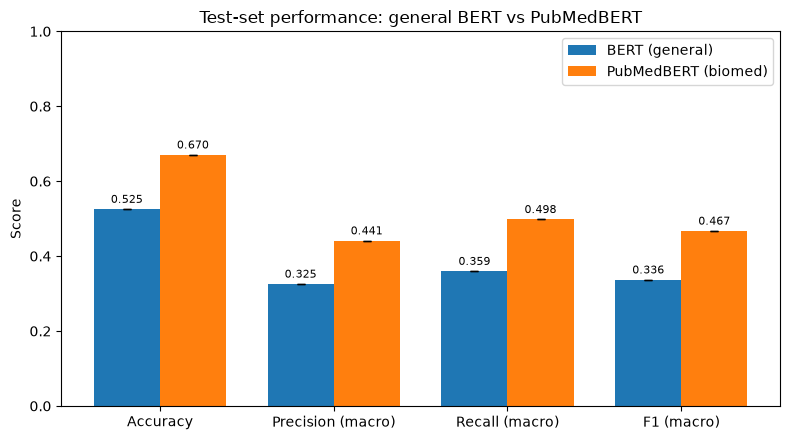

In [13]:
# Bar chart of the main metrics
plot_metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
means = results_df.groupby("model")[plot_metrics].mean().reindex(list(MODELS.keys()))
stds  = results_df.groupby("model")[plot_metrics].std().reindex(list(MODELS.keys())).fillna(0)

x = np.arange(len(plot_metrics)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, name in enumerate(means.index):
    bars = ax.bar(x + (i - 0.5) * w, means.loc[name], w, yerr=stds.loc[name], capsize=3, label=name)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}",
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"])
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Test-set performance: general BERT vs PubMedBERT")
ax.legend(); plt.tight_layout(); plt.show()

In [14]:
# Per-class precision / recall / F1 for the primary run of each model
y_true = test_df["label"].values
for name, ex_ in primary.items():
    print(f"\n{'-'*70}\n{name}\n{'-'*70}")
    print(classification_report(y_true, ex_["y_pred"], target_names=LABELS, digits=3, zero_division=0))


----------------------------------------------------------------------
BERT (general)
----------------------------------------------------------------------
              precision    recall  f1-score   support

         yes      0.568     0.755     0.648       110
          no      0.407     0.324     0.361        68
       maybe      0.000     0.000     0.000        22

    accuracy                          0.525       200
   macro avg      0.325     0.359     0.336       200
weighted avg      0.451     0.525     0.479       200


----------------------------------------------------------------------
PubMedBERT (biomed)
----------------------------------------------------------------------
              precision    recall  f1-score   support

         yes      0.739     0.773     0.756       110
          no      0.583     0.721     0.645        68
       maybe      0.000     0.000     0.000        22

    accuracy                          0.670       200
   macro avg      0.441   

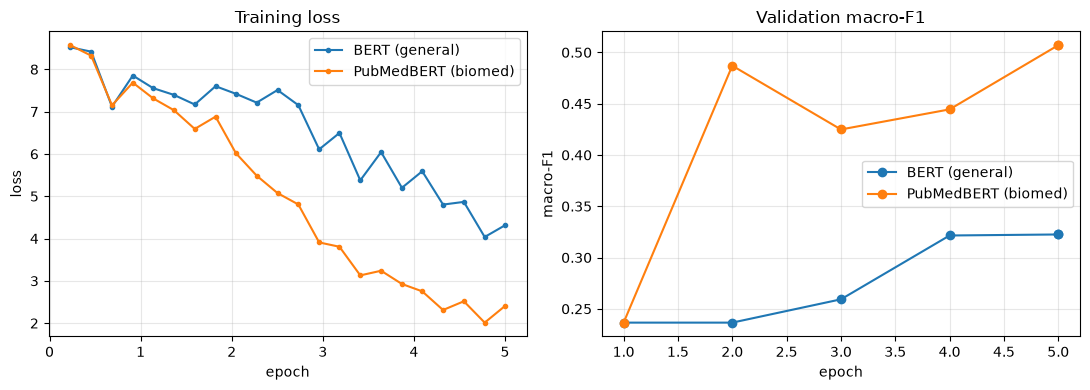

In [15]:
# Training curves (primary run of each model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, ex_ in primary.items():
    hist = ex_["log_history"]
    tr = [(h["epoch"], h["loss"]) for h in hist if "loss" in h]
    ev = [(h["epoch"], h["eval_f1_macro"]) for h in hist if "eval_f1_macro" in h]
    axes[0].plot(*zip(*tr), marker=".", label=name)
    axes[1].plot(*zip(*ev), marker="o", label=name)
axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[1].set_title("Validation macro-F1"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("macro-F1")
for a in axes: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [16]:
# Is the difference statistically meaningful? Exact McNemar test on the primary runs.
names = list(MODELS.keys())
a, b = names
ok_a = (primary[a]["y_pred"] == y_true)
ok_b = (primary[b]["y_pred"] == y_true)
only_a = int((ok_a & ~ok_b).sum())
only_b = int((~ok_a & ok_b).sum())
n_disc = only_a + only_b
p_val = binomtest(only_a, n_disc, 0.5).pvalue if n_disc > 0 else 1.0

print(f"Correct only with {a}: {only_a}")
print(f"Correct only with {b}: {only_b}")
print(f"McNemar exact p-value: {p_val:.4f}  ({'significant' if p_val < 0.05 else 'not significant'} at alpha=0.05)")
print("Note: with a 200-example test set, differences of a few points are often within noise.")

Correct only with BERT (general): 24
Correct only with PubMedBERT (biomed): 53
McNemar exact p-value: 0.0013  (significant at alpha=0.05)
Note: with a 200-example test set, differences of a few points are often within noise.


## 6. Predictions on custom examples

We wrote 6 new question and abstract pairs (not from PubMedQA) covering the three classes, including two deliberately ambiguous cases that should be *maybe*. Each model outputs a label and class probabilities.

In [17]:
custom_examples = [
    {
        "question": "Does regular aerobic exercise reduce systolic blood pressure in adults with hypertension?",
        "context": ("Hypertension is a major modifiable risk factor for cardiovascular disease. We conducted a randomized "
                    "controlled trial of 120 adults with stage 1 hypertension. Participants were assigned to 12 weeks of "
                    "supervised aerobic exercise three times per week or to usual care. Mean systolic blood pressure fell by "
                    "9.2 mmHg in the exercise group compared with 1.1 mmHg in controls (p < 0.001). No serious adverse events "
                    "were reported in either group."),
        "expected": "yes",
    },
    {
        "question": "Is vitamin C supplementation effective in preventing the common cold in the general population?",
        "context": ("We performed a systematic review and meta-analysis of 29 randomized trials including more than 11,000 "
                    "participants from the general population. Regular vitamin C supplementation did not reduce the incidence "
                    "of the common cold (risk ratio 0.97, 95% confidence interval 0.94 to 1.00). Only a modest reduction in "
                    "symptom duration was observed in some subgroups."),
        "expected": "no",
    },
    {
        "question": "Does preoperative anxiety predict postoperative pain after total knee arthroplasty?",
        "context": ("Anxiety before surgery has been linked to worse recovery. We followed 85 patients undergoing total knee "
                    "arthroplasty and measured anxiety scores before surgery and pain scores at 2 days and 6 weeks. Anxiety was "
                    "associated with higher pain at 2 days in women but not in men, and no association was found at 6 weeks. "
                    "The sample was small and the findings were inconsistent across subgroups, so larger studies are needed."),
        "expected": "maybe",
    },
    {
        "question": "Is metformin use associated with a lower risk of colorectal cancer in patients with type 2 diabetes?",
        "context": ("In this retrospective cohort study of 40,512 patients with type 2 diabetes, we compared colorectal cancer "
                    "incidence between metformin users and non-users over a median follow-up of 7 years. After adjustment for "
                    "age, sex, body mass index and smoking, metformin use was associated with a lower risk of colorectal "
                    "cancer (hazard ratio 0.78, 95% confidence interval 0.65 to 0.93)."),
        "expected": "yes",
    },
    {
        "question": "Does arthroscopic partial meniscectomy improve knee pain more than sham surgery in degenerative meniscal tears?",
        "context": ("We conducted a double-blind, sham-controlled randomized trial in 146 patients aged 35 to 65 years with "
                    "degenerative meniscal tears. At 12 months, there was no significant difference between the surgery and "
                    "sham groups in knee pain after exercise (difference 0.2 points, 95% confidence interval -0.9 to 1.3). "
                    "Rates of adverse events were similar in both groups."),
        "expected": "no",
    },
    {
        "question": "Can a single serum biomarker accurately diagnose early sepsis in emergency department patients?",
        "context": ("Early diagnosis of sepsis remains difficult. We evaluated a candidate serum biomarker in 310 emergency "
                    "department patients with suspected infection. The biomarker showed moderate sensitivity (74%) but low "
                    "specificity (58%), and its performance differed substantially between the derivation and validation "
                    "cohorts. External validation and combination with clinical scores are required before conclusions can be drawn."),
        "expected": "maybe",
    },
]
custom_df = pd.DataFrame(custom_examples)


def predict_custom(trainer, tokenizer, examples):
    model = trainer.model.eval()
    enc = tokenizer([e["question"] for e in examples], [e["context"] for e in examples],
                    truncation="only_second", max_length=MAX_LEN, padding=True, return_tensors="pt").to(model.device)
    with torch.no_grad():
        logits = model(**enc).logits.float().cpu().numpy()
    return softmax(logits)


rows = []
probs_by_model = {name: predict_custom(ex_["trainer"], ex_["tokenizer"], custom_examples) for name, ex_ in primary.items()}
for i, e in enumerate(custom_examples):
    row = {"#": i + 1, "question": e["question"][:70] + "...", "expected": e["expected"]}
    for name, probs in probs_by_model.items():
        j = int(probs[i].argmax())
        row[f"{name}"] = f"{id2label[j]} ({probs[i][j]:.2f})"
    rows.append(row)
custom_results = pd.DataFrame(rows)
custom_results

,#,question,expected,BERT (general),PubMedBERT (biomed)
0,1,Does regular aerobic exercise reduce systolic blood pressure in adults...,yes,yes (0.55),yes (0.94)
1,2,Is vitamin C supplementation effective in preventing the common cold i...,no,no (0.54),no (0.93)
2,3,Does preoperative anxiety predict postoperative pain after total knee ...,maybe,yes (0.81),no (0.56)
3,4,Is metformin use associated with a lower risk of colorectal cancer in ...,yes,no (0.57),yes (0.90)
4,5,Does arthroscopic partial meniscectomy improve knee pain more than sha...,no,yes (0.55),no (0.90)
5,6,Can a single serum biomarker accurately diagnose early sepsis in emerg...,maybe,no (0.56),no (0.40)


In [18]:
# Full class probabilities for each custom example
for i, e in enumerate(custom_examples):
    print(f"\n[{i+1}] {e['question']}\n    expected = {e['expected']}")
    for name, probs in probs_by_model.items():
        pr = "  ".join(f"{id2label[k]}={probs[i][k]:.3f}" for k in range(len(LABELS)))
        print(f"    {name:<22} {pr}")

for name, probs in probs_by_model.items():
    acc = np.mean([id2label[int(p.argmax())] == e["expected"] for p, e in zip(probs, custom_examples)])
    print(f"\nCustom-example accuracy, {name}: {acc:.2f} ({int(acc*len(custom_examples))}/{len(custom_examples)})")


[1] Does regular aerobic exercise reduce systolic blood pressure in adults with hypertension?
    expected = yes
    BERT (general)         yes=0.555  no=0.361  maybe=0.084
    PubMedBERT (biomed)    yes=0.936  no=0.028  maybe=0.036

[2] Is vitamin C supplementation effective in preventing the common cold in the general population?
    expected = no
    BERT (general)         yes=0.323  no=0.543  maybe=0.134
    PubMedBERT (biomed)    yes=0.020  no=0.933  maybe=0.046

[3] Does preoperative anxiety predict postoperative pain after total knee arthroplasty?
    expected = maybe
    BERT (general)         yes=0.814  no=0.125  maybe=0.061
    PubMedBERT (biomed)    yes=0.265  no=0.562  maybe=0.173

[4] Is metformin use associated with a lower risk of colorectal cancer in patients with type 2 diabetes?
    expected = yes
    BERT (general)         yes=0.264  no=0.575  maybe=0.161
    PubMedBERT (biomed)    yes=0.902  no=0.039  maybe=0.059

[5] Does arthroscopic partial meniscectomy improve 

## 7. Error analysis

We look at the errors from several angles:
1. Confusion matrices: *which* classes are confused?
2. Agreement between the two models.
3. Error rate by class and by input length.
4. Individual misclassified examples, especially confident mistakes.

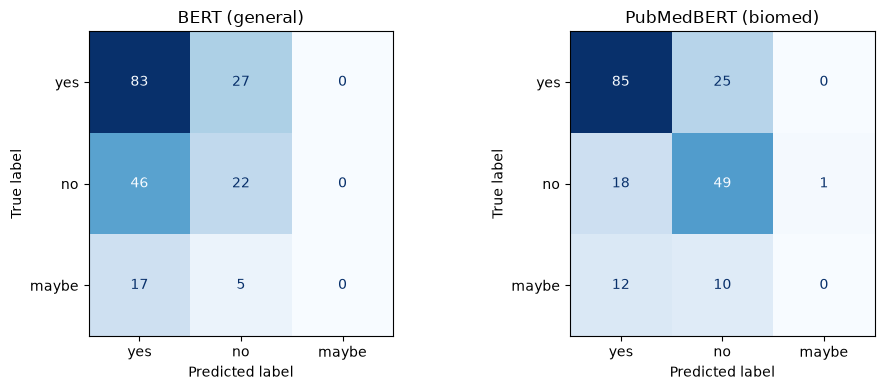

In [19]:
# 7.1 Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, ex_) in zip(axes, primary.items()):
    cm = confusion_matrix(y_true, ex_["y_pred"], labels=range(len(LABELS)))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [20]:
# 7.2 Build one analysis table for the test set
ana = test_df.copy()
ana["words"] = ana["context"].str.split().str.len()
for name, ex_ in primary.items():
    probs = softmax(ex_["logits"])
    ana[f"pred_{name}"] = [id2label[i] for i in ex_["y_pred"]]
    ana[f"conf_{name}"] = probs.max(axis=1)
    ana[f"ok_{name}"] = ex_["y_pred"] == ana["label"].values

a, b = list(MODELS.keys())
agree = pd.Series(
    np.select(
        [ana[f"ok_{a}"] & ana[f"ok_{b}"], ana[f"ok_{a}"] & ~ana[f"ok_{b}"], ~ana[f"ok_{a}"] & ana[f"ok_{b}"]],
        ["both correct", f"only {a} correct", f"only {b} correct"],
        default="both wrong",
    )
)
print("Agreement between the two models on the test set:")
print(agree.value_counts().to_string())

# Per-class recall (how often each true class is recovered)
recall_by_class = pd.DataFrame({
    name: [ana.loc[ana["label_name"] == l, f"ok_{name}"].mean() for l in LABELS]
    for name in MODELS
}, index=LABELS).round(3)
recall_by_class["support"] = [int((ana["label_name"] == l).sum()) for l in LABELS]
print("\nPer-class recall:")
print(recall_by_class.to_string())

Agreement between the two models on the test set:
both correct                        81
only PubMedBERT (biomed) correct    53
both wrong                          42
only BERT (general) correct         24

Per-class recall:
       BERT (general)  PubMedBERT (biomed)  support
yes             0.755                0.773      110
no              0.324                0.721       68
maybe           0.000                0.000       22


In [21]:
# 7.3 Error rate vs. input length (quartiles of abstract length)
ana["length_bin"] = pd.qcut(ana["words"], 4, labels=["Q1 (shortest)", "Q2", "Q3", "Q4 (longest)"])
err_by_len = pd.DataFrame({
    name: 1 - ana.groupby("length_bin", observed=True)[f"ok_{name}"].mean() for name in MODELS
}).round(3)
err_by_len["n"] = ana.groupby("length_bin", observed=True).size()
print("Error rate by abstract length:")
print(err_by_len.to_string())

# Truncation: how many test examples exceed the 512-token window for each tokenizer?
for name, tk in tok_cache.items():
    n_trunc = sum(len(tk(q, c)["input_ids"]) > MAX_LEN for q, c in zip(test_df["question"], test_df["context"]))
    print(f"{name}: {n_trunc}/{len(test_df)} test examples truncated at {MAX_LEN} tokens")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors


Error rate by abstract length:
               BERT (general)  PubMedBERT (biomed)   n
length_bin                                            
Q1 (shortest)           0.500                0.327  52
Q2                      0.529                0.314  51
Q3                      0.292                0.354  48
Q4 (longest)            0.571                0.327  49


BERT (general): 7/200 test examples truncated at 512 tokens
PubMedBERT (biomed): 3/200 test examples truncated at 512 tokens


In [22]:
# 7.4 Most confident mistakes of each model
for name in MODELS:
    wrong = ana[~ana[f"ok_{name}"]].sort_values(f"conf_{name}", ascending=False)
    print(f"\n{'='*90}\n{name}: {len(wrong)} errors out of {len(ana)}  (error rate {len(wrong)/len(ana):.1%})\n{'='*90}")
    view = wrong.head(8)[["question", "label_name", f"pred_{name}", f"conf_{name}", "words"]].copy()
    view["question"] = view["question"].str.slice(0, 95)
    view.columns = ["question", "true", "predicted", "confidence", "words"]
    print(view.round(3).to_string(index=False))


BERT (general): 95 errors out of 200  (error rate 47.5%)
                                                                                       question  true predicted  confidence  words
Outcome Feedback within Emergency Medicine Training Programs: An Opportunity to Apply the Theor maybe       yes       0.922    202
                         Is transurethral catheterisation the ideal method of bladder drainage?    no       yes       0.912    157
Is ganglionated plexi ablation during Maze IV procedure beneficial for postoperative long-term     no       yes       0.912    181
Medical student education in emergency medicine: do students meet the national standards for cl    no       yes       0.908    190
                                          Is the international normalised ratio (INR) reliable? maybe       yes       0.904    166
       Is fetal gender associated with emergency department visits for asthma during pregnancy?    no       yes       0.891    224
                         

In [23]:
# 7.5 Cases where the two models disagree
dis = ana[ana[f"ok_{a}"] != ana[f"ok_{b}"]].copy()
view = dis[["question", "label_name", f"pred_{a}", f"pred_{b}"]].head(10).copy()
view["question"] = view["question"].str.slice(0, 90)
view.columns = ["question", "true", f"pred {a}", f"pred {b}"]
print(f"{len(dis)} test examples where exactly one model is correct (showing up to 10):\n")
print(view.to_string(index=False))

77 test examples where exactly one model is correct (showing up to 10):

                                                                                  question true pred BERT (general) pred PubMedBERT (biomed)
Scrotal approach to both palpable and impalpable undescended testes: should it become our   yes                  no                      yes
Are polymorphisms in oestrogen receptors genes associated with lipid levels in response to  yes                 yes                       no
Do elderly patients benefit from surgery in addition to radiotherapy for treatment of meta   no                 yes                       no
          Is there a discrepancy between patient and physician quality of life assessment?  yes                 yes                       no
Is diffusion-weighted imaging a significant indicator of the development of vascularizatio   no                 yes                       no
Does left atrial appendage (LAA) occlusion device alter the echocardiography and 

In [24]:
# 7.6 Read a few mistakes in full (hardest cases = both models wrong)
both_wrong = ana[~ana[f"ok_{a}"] & ~ana[f"ok_{b}"]]
print(f"{len(both_wrong)} examples are misclassified by BOTH models.\n")
for _, r in both_wrong.head(3).iterrows():
    print("Q   :", r["question"])
    print("True:", r["label_name"], "| predicted:", r[f"pred_{a}"], "/", r[f"pred_{b}"])
    print("Abstract (first 500 chars):", r["context"][:500], "...\n")

42 examples are misclassified by BOTH models.

Q   : Are home sampling kits for sexually transmitted infections acceptable among men who have sex with men?
True: maybe | predicted: yes / yes
Abstract (first 500 chars): There is an urgent need to increase opportunistic screening for sexually transmitted infections (STIs) in community settings, particularly for those who are at increased risk including men who have sex with men (MSM). The aim of this qualitative study was to explore whether home sampling kits (HSK) for multiple bacterial STIs are potentially acceptable among MSM and to identify any concerns regarding their use. This study was developed as part of a formative evaluation of HSKs. Focus groups and  ...

Q   : Does aerobic fitness influence microvascular function in healthy adults at risk of developing Type 2 diabetes?
True: maybe | predicted: yes / yes
Abstract (first 500 chars): Twenty-seven healthy normal glucose-tolerant humans with either a previous diagnosis of gestati

In [25]:
# 7.7 Auto-generated summary of this run's findings
best = results_df.groupby("model")["f1_macro"].mean().idxmax()
worst = results_df.groupby("model")["f1_macro"].mean().idxmin()
gap_f1 = results_df.groupby("model")["f1_macro"].mean()[best] - results_df.groupby("model")["f1_macro"].mean()[worst]
gap_acc = results_df.groupby("model")["accuracy"].mean()[best] - results_df.groupby("model")["accuracy"].mean()[worst]

print(f"Best model by macro-F1: {best}")
print(f"  macro-F1 advantage over {worst}: {gap_f1:+.3f}")
print(f"  accuracy advantage over {worst}: {gap_acc:+.3f}")
print(f"  McNemar p-value (primary runs): {p_val:.3f}")
weakest = recall_by_class.drop(columns="support").mean(axis=1).idxmin()
print(f"Hardest class on average: '{weakest}' (recall {recall_by_class.drop(columns='support').loc[weakest].round(2).to_dict()})")
print(f"Tokens/word: " + ", ".join(f"{n}={frag.loc[n,'avg_tokens_per_word']:.2f}" for n in MODELS))

Best model by macro-F1: PubMedBERT (biomed)
  macro-F1 advantage over BERT (general): +0.130
  accuracy advantage over BERT (general): +0.145
  McNemar p-value (primary runs): 0.001
Hardest class on average: 'maybe' (recall {'BERT (general)': 0.0, 'PubMedBERT (biomed)': 0.0})
Tokens/word: BERT (general)=1.21, PubMedBERT (biomed)=1.05


## 8. Discussion

*Read this section together with the printed results above; the numbers will differ slightly between runs and hardware.*

**Why we expect the biomedical model to help.** PubMedBERT was pre-trained from scratch on PubMed abstracts with a vocabulary built from that text. Compared with `bert-base-uncased` it (i) keeps biomedical terms such as drug, disease and gene names as whole or few-piece tokens (see section 2.1), and (ii) has seen the typical structure of abstracts and the way results are phrased (e.g. "no significant difference", "hazard ratio"). Both matter for PubMedQA, where the answer usually hinges on how the results are stated.

**What to check in your own results.**
- *Accuracy vs macro-F1.* The class distribution is imbalanced (about 55% yes, 34% no, 11% maybe). Accuracy can look decent even if the model rarely predicts *maybe*, so compare macro-F1 and per-class recall.
- *The `maybe` class.* It is both the rarest and the most subjective class; annotators often disagree on it. Expect both models to find it the hardest, with the lowest recall in section 7.2.
- *Statistical significance.* With 200 test examples, a gap of a few points may not be significant (see the McNemar test). Running several seeds (`SEEDS = [42, 43, 44]`) gives a more reliable comparison, because fine-tuning on only 700 examples is noisy.
- *Error patterns.* Look at the confident mistakes and the examples where the models disagree: typical causes are abstracts that report mixed or subgroup-specific results, questions whose answer is the opposite of what the title suggests, and negated phrasing ("no difference") that flips the label.

**Limitations.**
- Only 1,000 labelled examples are used, so the models are fine-tuned on 700 examples and results have high variance.
- The 512-token limit truncates a minority of the longest abstracts.
- We did not use the larger `pqa_artificial` set or the reasoning-required setting that includes the long answer; the long answer was excluded on purpose because it leaks the label.
- Hyper-parameters were not tuned per model; both use the same settings for a fair comparison.

**Conclusion.** The notebook fine-tunes a general-domain BERT and a biomedical BERT on identical data and reports Accuracy, Precision, Recall and F1 on a held-out test set, together with custom-example predictions and an error analysis. Use the results table in section 5.1 and the summary printed in section 7.7 to state which model performed better in your run.

In [26]:
# Save results for the report / submission
os.makedirs("outputs", exist_ok=True)
results_df.to_csv("outputs/results_per_run.csv", index=False)
summary.to_csv("outputs/results_summary.csv")
ana.drop(columns=["length_bin"]).to_csv("outputs/test_predictions_and_errors.csv", index=False)
custom_results.to_csv("outputs/custom_example_predictions.csv", index=False)
print("Saved:", os.listdir("outputs"))

Saved: ['custom_example_predictions.csv', 'test_predictions_and_errors.csv', 'results_summary.csv', 'results_per_run.csv']
